##### Feladat (Példatár 6.1)

Az ábrán látható kilátó $P = 100 ~\mathrm{kN}$ nyomó terhelését az $L = 3.5 ~\mathrm{m}$ hosszúságú, $d = 100 ~\mathrm{mm}$ külső átmérőjű alumínium cső tartja, amelynek rugalmassági modulusza $E = 72 ~\mathrm{GPa}$. A cső alsó megtámasztása befogásnak tekinthető, míg a felső rögzítés a vízszintes elmozdulást gátolja, de az elfordulást megengedi. Mekkora legyen a cső $t$ falvastagsága, ha azt szeretnénk, hogy a tartó háromszoros biztonsággal feleljen meg kihajlásra? A választott anyag kritikus törőfeszültsége az Euler-féle képlet alkalmazási tartományának alsó határán $\sigma_0 = 480 ~\mathrm{MPa}$.

Adatok: $P = 100 ~\mathrm{kN}$, $L = 3.5 ~\mathrm{m}$, $d = 100 ~\mathrm{mm}$, $E = 72 ~\mathrm{GPa}$, $\sigma_0 = 480 ~\mathrm{MPa}$, $n = 3$.

Feladatok:

a) Mekkora legyen a cső $t$ falvastagsága, hogy $n = 3$ biztonság legyen kihajlásra?

<img src="img/01.jpg" alt="Feladat" width=180px>

##### Csomagok importálása

In [1]:
import numpy as np # Numerikus számítások
import matplotlib.pyplot as plt # Ábrázolás
plt.rcParams['mathtext.fontset'] = 'cm' # Betűtípus az ábrákon
plt.rcParams['font.family'] = 'serif' # Betűtípus az ábrákon
plt.rcParams['font.serif'] = ['cmr10'] # Betűtípus az ábrákon
plt.rcParams['axes.formatter.use_mathtext'] = True # Betűtípus az ábrákon
plt.rcParams['axes.unicode_minus'] = False # Betűtípus az ábrákon
from IPython.display import display, Math, Latex # Szép kimenet Jupyter notebookban
import sympy as sp # Szimbólikus számítások
from sympy import latex # Szép kimenet Jupyter notebookban
sp.init_printing() # Szép kimenet Jupyter notebookban

##### Adatok

In [2]:
P_data = 100 # kN
L_data = 3.5 # m
d_data = 100 # mm
E_data = 72 # GPa
sigma_0_data = 480 # MPa
n_data = 3 # Biztonsági tényező

# Átváltás N, mm, MPa rendszerbe
P_data = P_data * 10**3 # N
L_data = L_data * 10**3 # mm
E_data = E_data * 10**3 # MPa

In [3]:
P, L, d, E, sigma_0, n, t = sp.symbols('P, L, d, E, sigma_0, n, t')

In [4]:
data = [(P, P_data),
        (L, L_data),
        (d, d_data),
        (E, E_data),
        (sigma_0, sigma_0_data),
        (n, n_data)]

#### a) A cső $t$ falvastagsága

##### Megtámasztás módja

A cső alsó vége befogott, a felső rögzítés pedig a vízszintes elmozdulást gátolja, de az elfordulást megengedi (csukló). Ilyen befogott - csuklós megtámasztás esetén $c = 0.7$.

Az egyenértékű hossz (kihajlási hossz) a megtámasztás módjától függ:

$$L_0 = c \cdot L$$

<img src="img/02.jpg" alt="Feladat" width=600px>

In [5]:
c = 0.7 # Befogott - csuklós megtámasztás

# Egyenértékű hossz
L_0 = c * L
display(Math(rf'L_0 = c \cdot L = {latex(L_0.subs(data))} ~\mathrm{{mm}}'))

<IPython.core.display.Math object>

##### Törőerő

A tartónak $n = 3$-szoros biztonsággal kell megfelelnie kihajlásra, így a törőerő:

In [6]:
F_t = n * P
display(Math(rf'F_t = n \cdot P = {latex(F_t.subs(data))} ~\mathrm{{N}}'))

<IPython.core.display.Math object>

##### Kritikus feszültség a karcsúság függvényében

<img src="img/03.jpg" alt="Feladat" width=700px>

$$\lambda = \frac{L_0}{i_2}, \qquad \text{ahol} \quad i_2 = \sqrt{\frac{I_2}{A}}$$

ahol:
- $\lambda$: a karcsúsági tényező,
- $L_0$: az egyenértékű hossz,
- $i_2$: a minimális inerciasugár,
- $I_2$: a minimális másodrendű nyomaték,
- $A$: a keresztmetszet területe.

A karcsúsági tényező alapján:
- $\lambda < \lambda_F$: zömök rúd, a kritikus feszültség a folyáshatár ($\sigma_F$),
- $\lambda_F < \lambda < \lambda_0$: a kritikus feszültség a Tetmajer egyenesből számítható,
- $\lambda > \lambda_0$: karcsú rúd, a kritikus feszültség az Euler hiperbolából számítható.

##### Feltételezzük, hogy az Euler tartományban vagyunk ($\lambda > \lambda_0$)

Euler-féle törőerő:

$$F_t = \left( \frac{\pi}{L_0} \right)^2 \cdot I_2 \cdot E$$

ahol a körgyűrű keresztmetszet minimális másodrendű nyomatéka:

$$I_2 = \frac{\left( d^4 - (d - 2t)^4 \right) \pi}{64}$$

In [7]:
# Körgyűrű keresztmetszet minimális másodrendű nyomatéka
I_2 = (d**4 - (d - 2*t)**4) * sp.pi / 64
display(Math(rf'I_2 = {latex(I_2)}'))

# Euler-féle törőerő
F_t_Euler = (sp.pi / L_0)**2 * I_2 * E

<IPython.core.display.Math object>

##### Behelyettesítve

In [8]:
eq = (F_t_Euler - F_t).subs(data)
display(Math(rf'{latex(F_t.subs(data))} = \left( \frac{{\pi}}{{{latex(L_0.subs(data))}}} \right)^2 \cdot {latex(I_2.subs(data))} \cdot {latex(E.subs(data))}'))

<IPython.core.display.Math object>

##### Megoldás a falvastagságra

In [9]:
# Rendszer megoldása
sol = sp.solve(eq, t)

# Csak a fizikailag értelmes megoldás kell: valós és 0 < t < d/2
t_sol = [s for s in sol if s.is_real and 0 < s < d_data/2][0]
display(Math(rf't = {latex(round(t_sol, 3))} ~\mathrm{{mm}}'))

<IPython.core.display.Math object>

##### Ellenőrizzük a feltevést

In [10]:
# Keresztmetszet területe
A = (d**2 - (d - 2*t)**2) * sp.pi / 4
A_sol = A.subs(data).subs(t, t_sol)
display(Math(rf'A = \frac{{\left( d^2 - (d-2t)^2 \right) \pi}}{{4}} = {latex(round(A_sol, 2))} ~\mathrm{{mm^2}}'))

# Minimális másodrendű nyomaték
I_2_sol = I_2.subs(data).subs(t, t_sol)
display(Math(rf'I_2 = \frac{{\left( d^4 - (d-2t)^4 \right) \pi}}{{64}} = {latex(round(I_2_sol, 2))} ~\mathrm{{mm^4}}'))

# Minimális inerciasugár
i_2_sol = sp.sqrt(I_2_sol / A_sol)
display(Math(rf'i_2 = \sqrt{{\frac{{I_2}}{{A}}}} = {latex(round(i_2_sol, 3))} ~\mathrm{{mm}}'))

# Karcsúsági tényező
lambda_sol = L_0.subs(data) / i_2_sol
display(Math(rf'\lambda = \frac{{L_0}}{{i_2}} = {latex(round(lambda_sol, 2))}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### $\lambda_0$ számítható $\sigma_0$ segítségével

$$\sigma_0 = \frac{\pi^2 \cdot E}{\lambda_0^2} \quad \rightarrow \quad \lambda_0 = \sqrt{\frac{\pi^2 \cdot E}{\sigma_0}}$$

In [11]:
lambda_0 = sp.sqrt(sp.pi**2 * E / sigma_0)
lambda_0_sol = lambda_0.subs(data)
display(Math(rf'\lambda_0 = \sqrt{{\frac{{\pi^2 \cdot E}}{{\sigma_0}}}} = {latex(round(lambda_0_sol, 2))}'))

<IPython.core.display.Math object>

In [12]:
# A feltételezés ellenőrzése
if lambda_sol > lambda_0_sol:
    display(Latex(rf'Mivel $\lambda = {round(lambda_sol, 2)} > \lambda_0 = {round(lambda_0_sol, 2)}$, a feltételezés helyes volt!'))
else:
    display(Latex(rf'Mivel $\lambda = {round(lambda_sol, 2)} \leq \lambda_0 = {round(lambda_0_sol, 2)}$, a feltételezés nem volt helyes!'))

<IPython.core.display.Latex object>

##### Ábrázolás

Az Euler hiperbola ($\sigma_t = \frac{\pi^2 \cdot E}{\lambda^2}$) csak a $\lambda > \lambda_0$ tartományban érvényes. A cső kritikus feszültsége a törőerőből: $\sigma_t = \frac{F_t}{A}$.

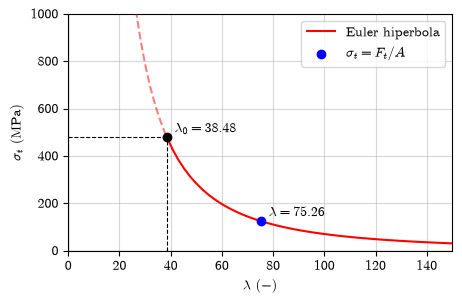

In [13]:
# Numerikus értékek
E_num = float(E.subs(data))
sigma_0_num = float(sigma_0.subs(data))
lambda_0_num = float(lambda_0_sol)
lambda_num = float(lambda_sol)
sigma_t_num = float(F_t.subs(data) / A_sol) # A cső kritikus feszültsége

# x értékek
lambda_vals = np.linspace(lambda_0_num, 150) # Érvényességi tartomány
lambda_vals_ki = np.linspace(20, lambda_0_num) # Érvényességi tartományon kívül

# y értékek
sigma_vals = np.pi**2 * E_num / lambda_vals**2
sigma_vals_ki = np.pi**2 * E_num / lambda_vals_ki**2

# Ábrázolás
plt.figure(figsize=(12/2.54, 8/2.54))
plt.plot(lambda_vals, sigma_vals, color='red', zorder=5, label='Euler hiperbola')
plt.plot(lambda_vals_ki, sigma_vals_ki, color='red', linestyle='--', alpha=0.5, zorder=5)
plt.plot([lambda_0_num, lambda_0_num], [0, sigma_0_num], color='black', linestyle='--', linewidth=0.8)
plt.plot([0, lambda_0_num], [sigma_0_num, sigma_0_num], color='black', linestyle='--', linewidth=0.8)
plt.scatter(lambda_0_num, sigma_0_num, color='black', zorder=6)
plt.scatter(lambda_num, sigma_t_num, color='blue', zorder=6, label=r'$\sigma_t = F_t / A$')
plt.text(lambda_0_num + 3, sigma_0_num + 20, rf'$\lambda_0 = {lambda_0_num:.2f}$')
plt.text(lambda_num + 3, sigma_t_num + 20, rf'$\lambda = {lambda_num:.2f}$')
plt.axvline(0, color='black', linewidth=0.8)
plt.axhline(0, color='black', linewidth=0.8)
plt.xlabel(r'$\lambda ~ \mathrm{(-)}$')
plt.ylabel(r'$\sigma_t ~ \mathrm{(MPa)}$')
plt.grid(True, alpha=0.5)
plt.xlim(0, 150)
plt.ylim(0, 1000)
plt.legend()
plt.tight_layout()
plt.savefig('euler_hiperbola.pdf')
plt.show()

A cső a karcsú rudak tartományába esik, így az Euler-féle képlet valóban alkalmazható. A szükséges falvastagság $t \approx 8.3 ~\mathrm{mm}$.